In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

from IPython.display import display

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
dataset=load_breast_cancer()

X=pd.DataFrame (dataset.data, columns=dataset.feature_names)
y=pd.Series( (dataset.target == 0).astype(int), name ="actual_malignant" )
df = X.copy()
df["actual_malignant"]=y

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,actual_malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [4]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
display(
    y.value_counts()
      .rename(index={0: "Benign", 1: "Malignant"})
      .to_frame("Count")
)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

,Missing Values
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0



Duplicate rows: 0

Class distribution:


,Count
actual_malignant,
Benign,357
Malignant,212


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 455
Testing observations: 114


In [6]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


In [7]:
y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

results = X_test.copy()

results["actual"] = y_test
results["predicted"] = y_pred
results["malignant_probability"] = y_probability

results["actual_label"] = results["actual"].map({
    0: "Benign",
    1: "Malignant"
})

results["predicted_label"] = results["predicted"].map({
    0: "Benign",
    1: "Malignant"
})

display(results.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,actual,predicted,malignant_probability,actual_label,predicted_label
120,11.41,10.82,73.34,403.3,0.09373,0.06685,0.03512,0.02623,0.1667,0.06113,...,0.2390,0.21020,0.08958,0.3016,0.08523,0,0,0.000365,Benign,Benign
250,20.94,23.56,138.90,1364.0,0.10070,0.16060,0.27120,0.13100,0.2205,0.05898,...,0.3172,0.69910,0.21050,0.3126,0.07849,1,1,1.000000,Malignant,Malignant
375,16.17,16.07,106.30,788.5,0.09880,0.14380,0.06651,0.05397,0.1990,0.06572,...,0.2550,0.21140,0.12510,0.3153,0.08960,0,0,0.042568,Benign,Benign
99,14.42,19.77,94.48,642.5,0.09752,0.11410,0.09388,0.05839,0.1879,0.06390,...,0.3026,0.31940,0.15650,0.2718,0.09353,1,1,0.576187,Malignant,Malignant
455,13.38,30.72,86.34,557.2,0.09245,0.07426,0.02819,0.03264,0.1375,0.06016,...,0.1421,0.07003,0.07763,0.2196,0.07675,0,1,0.509155,Benign,Malignant


In [8]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_probability)
}

metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Score"]
)

metrics_df["Score"] = metrics_df["Score"].round(4)

display(metrics_df)

,Metric,Score
0,Accuracy,0.9649
1,Precision,0.9750
2,Recall,0.9286
3,F1 Score,0.9512
4,ROC-AUC,0.9960


In [9]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Benign", "Malignant"],
        digits=4
    )
)

              precision    recall  f1-score   support

      Benign     0.9595    0.9861    0.9726        72
   Malignant     0.9750    0.9286    0.9512        42

    accuracy                         0.9649       114
   macro avg     0.9672    0.9573    0.9619       114
weighted avg     0.9652    0.9649    0.9647       114



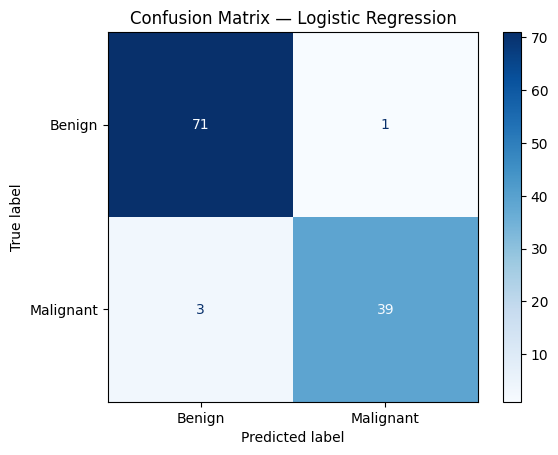

In [10]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

display_labels = ["Benign", "Malignant"]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Logistic Regression")
plt.show()

In [11]:
results["error_type"] = np.select(
    [
        (results["actual"] == 0) & (results["predicted"] == 1),
        (results["actual"] == 1) & (results["predicted"] == 0)
    ],
    [
        "False Positive",
        "False Negative"
    ],
    default="Correct Prediction"
)

error_summary = (
    results["error_type"]
    .value_counts()
    .rename_axis("Outcome")
    .reset_index(name="Count")
)

display(error_summary)

,Outcome,Count
0,Correct Prediction,110
1,False Negative,3
2,False Positive,1


In [12]:
false_negatives = results[
    results["error_type"] == "False Negative"
]

print("Number of false negatives:", len(false_negatives))

display(
    false_negatives[
        [
            "actual_label",
            "predicted_label",
            "malignant_probability",
            "mean radius",
            "mean texture",
            "mean perimeter"
        ]
    ]
)

Number of false negatives: 3


,actual_label,predicted_label,malignant_probability,mean radius,mean texture,mean perimeter
73,Malignant,Benign,0.061429,13.80,15.79,90.43
190,Malignant,Benign,0.314532,14.22,23.12,94.37
205,Malignant,Benign,0.491610,15.12,16.68,98.78


In [13]:
false_positives = results[
    results["error_type"] == "False Positive"
]

print("Number of false positives:", len(false_positives))

display(
    false_positives[
        [
            "actual_label",
            "predicted_label",
            "malignant_probability",
            "mean radius",
            "mean texture",
            "mean perimeter"
        ]
    ]
)

Number of false positives: 1


,actual_label,predicted_label,malignant_probability,mean radius,mean texture,mean perimeter
455,Benign,Malignant,0.509155,13.38,30.72,86.34


In [14]:
category_results = results.copy()

category_results["radius_group"] = pd.qcut(
    category_results["mean radius"],
    q=4,
    duplicates="drop"
)

group_metrics = (
    category_results
    .groupby("radius_group", observed=True)
    .apply(
        lambda group: pd.Series({
            "Observations": len(group),
            "Accuracy": accuracy_score(
                group["actual"],
                group["predicted"]
            ),
            "Precision": precision_score(
                group["actual"],
                group["predicted"],
                zero_division=0
            ),
            "Recall": recall_score(
                group["actual"],
                group["predicted"],
                zero_division=0
            ),
            "F1 Score": f1_score(
                group["actual"],
                group["predicted"],
                zero_division=0
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(group_metrics.round(4))

,radius_group,Observations,Accuracy,Precision,Recall,F1 Score
0,"(7.7589999999999995, 11.608]",29.0,1.0000,0.0000,0.00,0.0000
1,"(11.608, 13.43]",28.0,0.9643,0.6667,1.00,0.8000
2,"(13.43, 15.302]",28.0,0.8929,1.0000,0.75,0.8571
3,"(15.302, 23.09]",29.0,1.0000,1.0000,1.00,1.0000


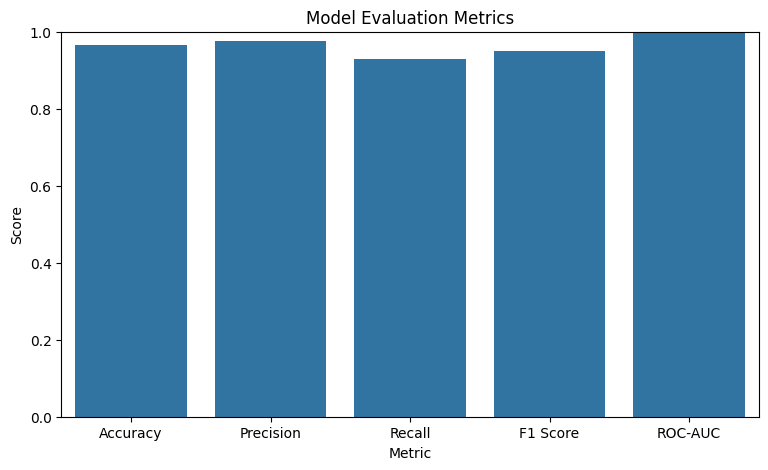

In [15]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=metrics_df,
    x="Metric",
    y="Score"
)

plt.ylim(0, 1)
plt.title("Model Evaluation Metrics")
plt.ylabel("Score")
plt.xlabel("Metric")

plt.show()

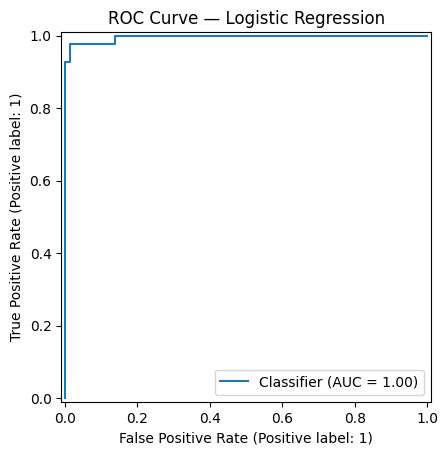

In [16]:
RocCurveDisplay.from_predictions(
    y_test,
    y_probability
)

plt.title("ROC Curve — Logistic Regression")
plt.show()

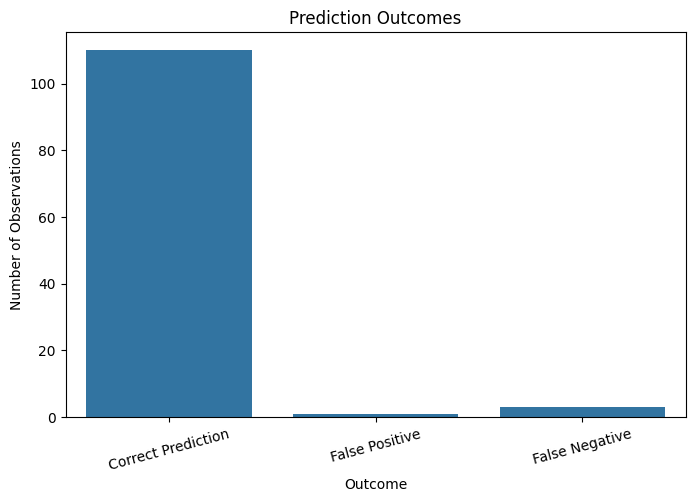

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=results,
    x="error_type",
    order=[
        "Correct Prediction",
        "False Positive",
        "False Negative"
    ]
)

plt.title("Prediction Outcomes")
plt.xlabel("Outcome")
plt.ylabel("Number of Observations")
plt.xticks(rotation=15)

plt.show()

In [18]:
summary = pd.DataFrame({
    "Metric": [
        "Total Test Observations",
        "Correct Predictions",
        "False Positives",
        "False Negatives",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Value": [
        len(y_test),
        int((y_test == y_pred).sum()),
        int(((y_test == 0) & (y_pred == 1)).sum()),
        int(((y_test == 1) & (y_pred == 0)).sum()),
        metrics["Accuracy"],
        metrics["Precision"],
        metrics["Recall"],
        metrics["F1 Score"],
        metrics["ROC-AUC"]
    ]
})

display(summary)

,Metric,Value
0,Total Test Observations,114.000000
1,Correct Predictions,110.000000
2,False Positives,1.000000
3,False Negatives,3.000000
4,Accuracy,0.964912
5,Precision,0.975000
6,Recall,0.928571
7,F1 Score,0.951220
8,ROC-AUC,0.996032


In [19]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

metrics_df.to_csv(
    output_dir / "evaluation_metrics.csv",
    index=False
)

results.to_csv(
    output_dir / "prediction_results.csv",
    index=False
)

error_summary.to_csv(
    output_dir / "error_summary.csv",
    index=False
)

group_metrics.to_csv(
    output_dir / "subgroup_performance.csv",
    index=False
)

print("Output files saved.")

Output files saved.


In [20]:
report = f"""
# AI Model Evaluation & Error Analysis

## Project Overview

This project evaluates a Logistic Regression classification model
using the Wisconsin Breast Cancer Diagnostic dataset.

The model predicts whether an observation is malignant or benign.
This is a benchmark analysis and not a medical diagnostic tool.

## Model

- Algorithm: Logistic Regression
- Feature scaling: StandardScaler
- Train-test split: 80% training, 20% testing
- Random state: 42
- Positive class: Malignant

## Evaluation Metrics

- Accuracy: {metrics['Accuracy']:.4f}
- Precision: {metrics['Precision']:.4f}
- Recall: {metrics['Recall']:.4f}
- F1 Score: {metrics['F1 Score']:.4f}
- ROC-AUC: {metrics['ROC-AUC']:.4f}

## Error Analysis

- False Positives: {len(false_positives)}
- False Negatives: {len(false_negatives)}

A false negative represents an actual malignant observation
that the model predicted as benign.

A false positive represents an actual benign observation
that the model predicted as malignant.

## Interpretation

The metrics describe the model's performance on the held-out
test dataset. Recall measures the proportion of actual malignant
observations detected by the model.

The confusion matrix and error tables should be examined to
understand the types of mistakes made by the classifier.

## Limitations

- This is a small benchmark dataset.
- Results depend on the selected train-test split.
- The model is not intended for clinical use.
- Subgroup analysis is exploratory.
- The model does not establish causal relationships.

## Conclusion

The project demonstrates model evaluation, classification
metrics, error analysis, and subgroup performance comparison
using Python and scikit-learn.
"""

with open(
    output_dir / "model_evaluation_report.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print("Report generated.")

Report generated.


In [21]:
import shutil
from google.colab import files

shutil.make_archive(
    "ai_model_evaluation_outputs",
    "zip",
    "outputs"
)

files.download("ai_model_evaluation_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>